# 06 · Figures de la présentation

Figures de l'histoire racontée en 10 minutes (plan dans le doc partagé). Elles relisent les résultats des runs Chav (`data/processed/runs/v3`, `transport`, `screen3`) et refont les régressions par famille protéique ; tout est exporté dans `reports/figures/06_*`. La carte t-SNE `06_tsne_islands.png` refait celle du notebook 03 (section F).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

from acc.data import PROJECT_ROOT, load_raw
from acc.predict import (
    POSITIVITY,
    TARGETS,
    common_panel,
    demographic_features,
    labels_for,
    protein_family_features,
)
from acc.score import wilson

warnings.filterwarnings("ignore")
RUNS = PROJECT_ROOT / "data" / "processed" / "runs"
FIG = PROJECT_ROOT / "reports" / "figures"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": MUTED,
})

df = load_raw()
panel = common_panel(df)


def frame(target):
    y = labels_for(TARGETS[target], df)
    return df[y.notna()], y.dropna().to_numpy().astype(int)

## A. Le piège du centre

Prévalence de l'antécédent d'anaphylaxie par région, et AUC sur une région tenue à part (`runs/transport`).

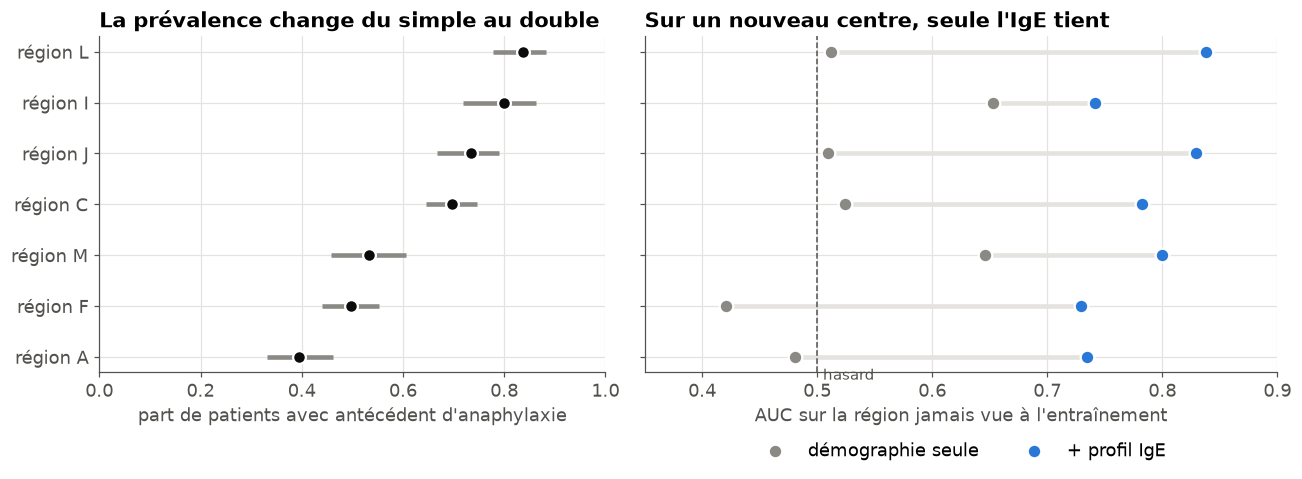

In [2]:
sub, y = frame("food_anaphylaxis")
region = sub["French_Region"].fillna("unknown")
tr = pd.read_csv(RUNS / "transport" / "transport.csv")
t = tr[(tr.target == "food_anaphylaxis") & (tr.model == "hgb")].pivot_table(index="region", columns="features", values="auc")
prev = pd.Series(y, index=sub.index).groupby(region).agg(["mean", "size"]).loc[t.index]
order = prev.sort_values("mean").index

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
yy = np.arange(len(order))
ci = np.array([wilson(int(round(m * n)), int(n)) for m, n in prev.loc[order].values])
a1.hlines(yy, ci[:, 0], ci[:, 1], color=GRAY, lw=3)
a1.scatter(prev.loc[order, "mean"], yy, s=70, color=INK, zorder=3, edgecolors="white", linewidths=1.5)
a1.set_yticks(yy, [f"région {r.removeprefix('region')}" for r in order])
a1.set_xlim(0, 1)
a1.set_xlabel("part de patients avec antécédent d'anaphylaxie")
a1.set_title("La prévalence change du simple au double", loc="left")
for lab, col, fs in [("démographie seule", GRAY, "demo"), ("+ profil IgE", BLUE, "demo+ige")]:
    a2.scatter(t.loc[order, fs], yy, s=80, color=col, zorder=3, edgecolors="white", linewidths=1.5, label=lab)
a2.hlines(yy, t.loc[order, "demo"], t.loc[order, "demo+ige"], color=GRID, lw=3, zorder=1)
a2.axvline(0.5, color=MUTED, lw=1, ls="--")
a2.text(0.505, -0.45, "hasard", color=MUTED, fontsize=10)
a2.set_yticks(yy, [""] * len(order))
a2.set_xlim(0.35, 0.9)
a2.set_xlabel("AUC sur la région jamais vue à l'entraînement")
a2.set_title("Sur un nouveau centre, seule l'IgE tient", loc="left")
a2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout()
fig.savefig(FIG / "06_trap_centre.png", dpi=200, bbox_inches="tight")
plt.show()

## B. Le piège de la polysensibilisation

Risque selon le nombre d'allergènes positifs, et nombre d'allergènes « significatifs » avant / après ajustement (`runs/screen3`).

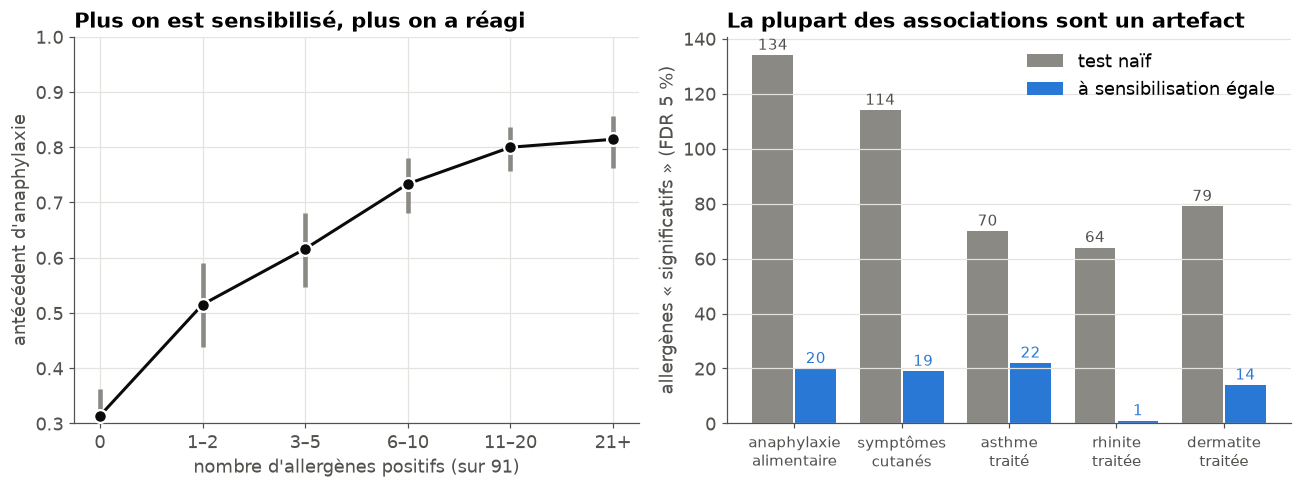

In [3]:
npos = (sub[panel] >= POSITIVITY).sum(axis=1)
bins = pd.cut(npos, [-1, 0, 2, 5, 10, 20, 100], labels=["0", "1–2", "3–5", "6–10", "11–20", "21+"])
g = pd.Series(y, index=sub.index).groupby(bins, observed=True).agg(["mean", "size"])
screen = pd.read_csv(RUNS / "screen3" / "screen.csv")
nsig = screen.groupby(["target", "adjustment"])["q"].apply(lambda q: int((q < 0.05).sum())).unstack()
show = ["food_anaphylaxis", "skin_symptoms", "asthma_treatment", "rhinitis_treatment", "ad_treatment"]
labels = {"food_anaphylaxis": "anaphylaxie\nalimentaire", "skin_symptoms": "symptômes\ncutanés",
          "asthma_treatment": "asthme\ntraité", "rhinitis_treatment": "rhinite\ntraitée", "ad_treatment": "dermatite\ntraitée"}

fig, (b1, b2) = plt.subplots(1, 2, figsize=(12, 4.6))
x = np.arange(len(g))
ci = np.array([wilson(int(round(m * n)), int(n)) for m, n in g.values])
b1.vlines(x, ci[:, 0], ci[:, 1], color=GRAY, lw=3)
b1.plot(x, g["mean"], color=INK, lw=2, zorder=2)
b1.scatter(x, g["mean"], s=70, color=INK, zorder=3, edgecolors="white", linewidths=1.5)
b1.set_xticks(x, g.index)
b1.set_ylim(0.3, 1)
b1.set_xlabel("nombre d'allergènes positifs (sur 91)")
b1.set_ylabel("antécédent d'anaphylaxie")
b1.set_title("Plus on est sensibilisé, plus on a réagi", loc="left")
xb = np.arange(len(show))
raw = nsig.loc[show, "demo"].to_numpy()
adj = nsig.loc[show, "demo+npos"].to_numpy()
b2.bar(xb - 0.2, raw, width=0.38, color=GRAY, label="test naïf")
b2.bar(xb + 0.2, adj, width=0.38, color=BLUE, label="à sensibilisation égale")
for i, (r, a) in enumerate(zip(raw, adj)):
    b2.text(i - 0.2, r + 2, str(r), ha="center", fontsize=10, color=MUTED)
    b2.text(i + 0.2, a + 2, str(a), ha="center", fontsize=10, color=BLUE)
b2.set_xticks(xb, [labels[s] for s in show], fontsize=10)
b2.set_ylabel("allergènes « significatifs » (FDR 5 %)")
b2.set_title("La plupart des associations sont un artefact", loc="left")
b2.legend(frameon=False)
b2.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "06_trap_polysensitization.png", dpi=200, bbox_inches="tight")
plt.show()

## C. La carte familles protéiques × maladies

OR par allergène positif de plus dans chaque famille (logistique sur toutes les données, ajustée âge, puce, région et autres familles), BH sur les 56 cases.

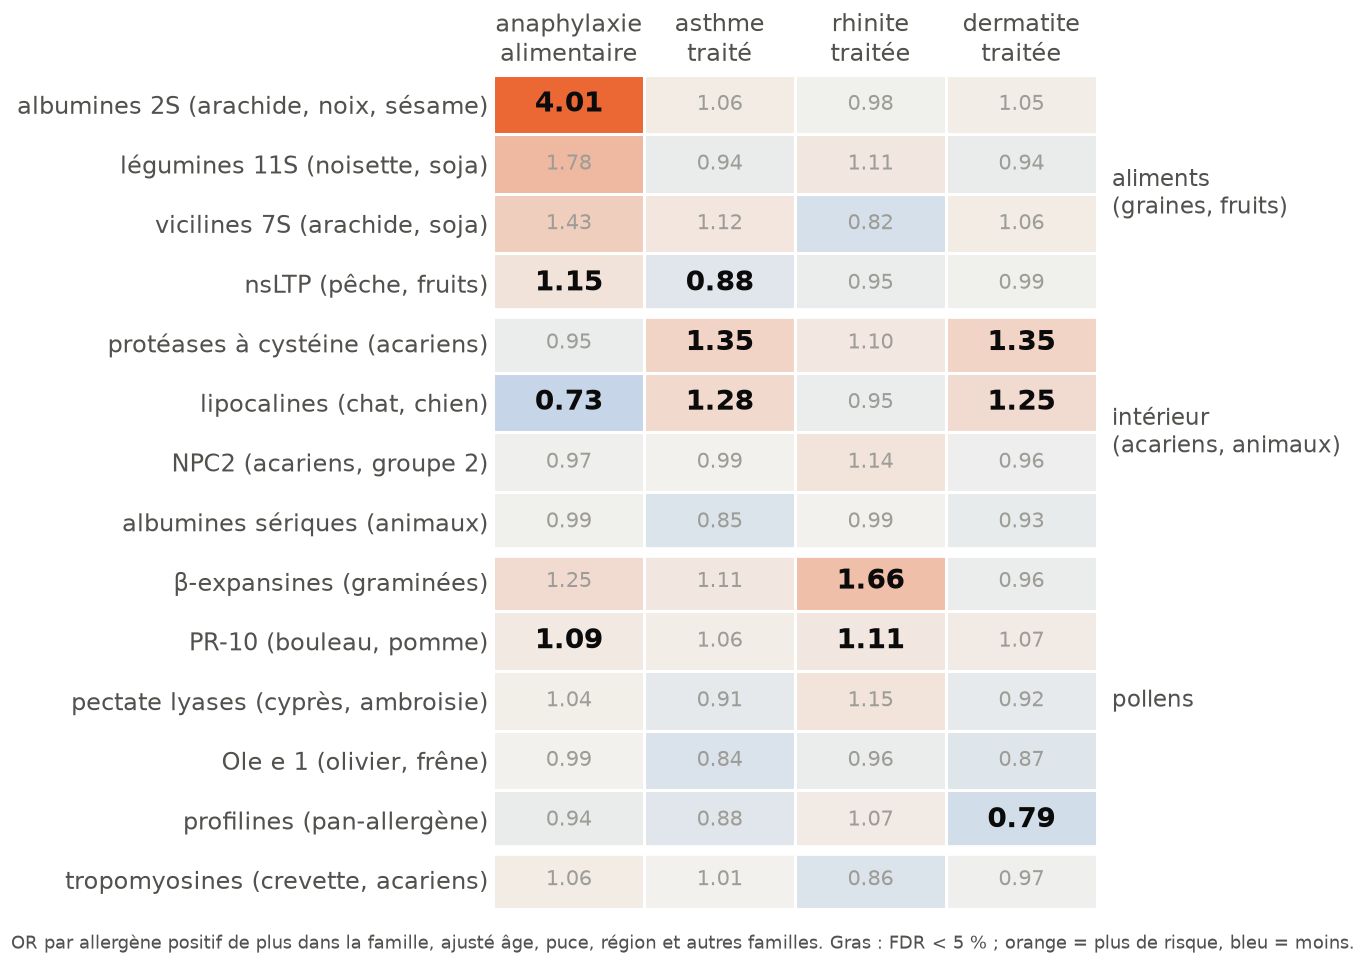

                          food_anaphylaxis  asthma_treatment  rhinitis_treatment  ad_treatment
pfam_2S albumin                       4.01              1.06                0.98          1.05
pfam_11S legumin                      1.78              0.94                1.11          0.94
pfam_7S vicilin                       1.43              1.12                0.82          1.06
pfam_nsLTP                            1.15              0.88                0.95          0.99
pfam_Cysteine protease                0.95              1.35                1.10          1.35
pfam_Lipocalin                        0.73              1.28                0.95          1.25
pfam_NPC2 (mite group 2)              0.97              0.99                1.14          0.96
pfam_Serum albumin                    0.99              0.85                0.99          0.93
pfam_Beta-expansin                    1.25              1.11                1.66          0.96
pfam_PR-10                            1.09        

In [4]:
def pfam_logit(target):
    sub, y = frame(target)
    X = protein_family_features(sub, panel).drop(columns=["npos_total", "pfam_storage_all"])
    X = X.loc[:, X.std() > 0]
    d = demographic_features(sub).drop(columns=["Gender"])
    d["Age"] = d["Age"] / 10
    for prefix in ["chip_", "region_"]:
        d = d.drop(columns=[c for c in d if c.startswith(prefix)][0])
    Z = sm.add_constant(pd.concat([X, d], axis=1))
    ok = Z.notna().all(axis=1).to_numpy()
    fit = sm.Logit(y[ok], Z[ok]).fit(disp=0)
    return pd.DataFrame({"log_or": fit.params[X.columns], "p": fit.pvalues[X.columns]})


MAP_TARGETS = {"food_anaphylaxis": "anaphylaxie\nalimentaire",
               "asthma_treatment": "asthme\ntraité", "rhinitis_treatment": "rhinite\ntraitée",
               "ad_treatment": "dermatite\ntraitée"}
res = {t: pfam_logit(t) for t in MAP_TARGETS}
lor = pd.DataFrame({t: r["log_or"] for t, r in res.items()})
pv = pd.DataFrame({t: r["p"] for t, r in res.items()})
from statsmodels.stats.multitest import multipletests  # noqa: E402

q = pd.DataFrame(multipletests(pv.to_numpy().ravel(), method="fdr_bh")[1].reshape(pv.shape), index=pv.index, columns=pv.columns)
FAMILY_LABELS = {
    "pfam_2S albumin": "albumines 2S (arachide, noix, sésame)", "pfam_11S legumin": "légumines 11S (noisette, soja)",
    "pfam_7S vicilin": "vicilines 7S (arachide, soja)", "pfam_nsLTP": "nsLTP (pêche, fruits)",
    "pfam_PR-10": "PR-10 (bouleau, pomme)", "pfam_Profilin": "profilines (pan-allergène)",
    "pfam_Beta-expansin": "β-expansines (graminées)", "pfam_Ole e 1-like": "Ole e 1 (olivier, frêne)",
    "pfam_Pectate lyase": "pectate lyases (cyprès, ambroisie)", "pfam_Cysteine protease": "protéases à cystéine (acariens)",
    "pfam_NPC2 (mite group 2)": "NPC2 (acariens, groupe 2)", "pfam_Lipocalin": "lipocalines (chat, chien)",
    "pfam_Serum albumin": "albumines sériques (animaux)", "pfam_Tropomyosin": "tropomyosines (crevette, acariens)",
    "pfam_other": "autres",
}
GROUPS = [
    ["pfam_2S albumin", "pfam_11S legumin", "pfam_7S vicilin", "pfam_nsLTP"],
    ["pfam_Cysteine protease", "pfam_Lipocalin", "pfam_NPC2 (mite group 2)", "pfam_Serum albumin"],
    ["pfam_Beta-expansin", "pfam_PR-10", "pfam_Pectate lyase", "pfam_Ole e 1-like", "pfam_Profilin"],
    ["pfam_Tropomyosin"],
]
GROUP_NAMES = ["aliments\n(graines, fruits)", "intérieur\n(acariens, animaux)", "pollens", ""]
rows = [r for g in GROUPS for r in g]
L = lor.loc[rows]
Q = q.loc[rows]
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f3f2ee", ORANGE])
lim = 1.4  # log OR (OR 0.25 .. 4)
fig, ax = plt.subplots(figsize=(12.5, 8.8))
ax.imshow(L.to_numpy(), cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        orv = np.exp(L.iat[i, j])
        sig = Q.iat[i, j] < 0.05
        ax.text(j, i, f"{orv:.2f}", ha="center", va="center", fontsize=18 if sig else 14,
                fontweight="bold" if sig else "normal", color=INK if sig else "#9d9c97")
ax.set_xticks(range(L.shape[1]), list(MAP_TARGETS.values()), fontsize=16)
ax.set_yticks(range(L.shape[0]), [FAMILY_LABELS[r] for r in rows], fontsize=16)
ax.xaxis.tick_top()
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, L.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, L.shape[0]), minor=True)
ax.grid(which="minor", color="white", lw=2)
ax.tick_params(which="both", length=0)
edge = -0.5
for g, name in zip(GROUPS, GROUP_NAMES):
    if edge > -0.5:
        ax.axhline(edge, color="white", lw=7)
    if name:
        ax.text(L.shape[1] - 0.4, edge + len(g) / 2, name, va="center", ha="left", fontsize=15, color=MUTED)
    edge += len(g)
fig.text(0.01, 0.01, "OR par allergène positif de plus dans la famille, ajusté âge, puce, région et autres familles. "
         "Gras : FDR < 5 % ; orange = plus de risque, bleu = moins.", fontsize=12, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "06_family_map.png", dpi=200, bbox_inches="tight")
plt.show()
print(np.exp(L).round(2).to_string())
print((Q < 0.05).sum())

## D. Le type de protéine, au-delà de la quantité

`demo` → `demo+npos` (nombre de positifs, IgE max) → `demo+pfam` (comptes par famille), gradient boosting, `runs/v3`.

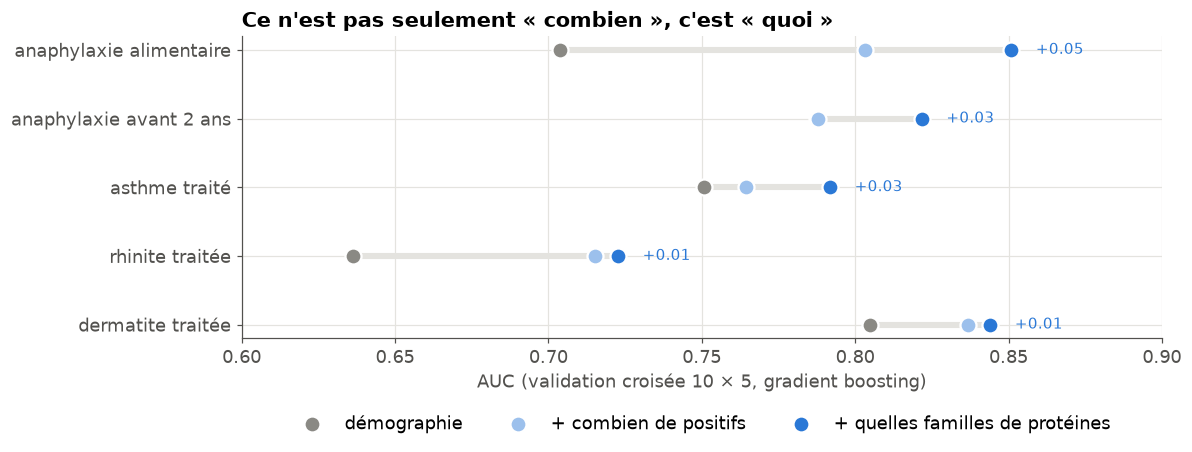

In [5]:
from acc.score import corrected_ci  # noqa: E402

v3 = pd.read_csv(RUNS / "v3" / "folds.csv")
v3h = v3[v3.model == "hgb"]
TV = {"food_anaphylaxis": "anaphylaxie alimentaire", "early_food_anaphylaxis": "anaphylaxie avant 2 ans",
      "asthma_treatment": "asthme traité", "rhinitis_treatment": "rhinite traitée", "ad_treatment": "dermatite traitée"}
fig, ax = plt.subplots(figsize=(11, 4.4))
yy = np.arange(len(TV))[::-1]
steps = [("demo", GRAY, "démographie"), ("demo+npos", "#9cc0ec", "+ combien de positifs"),
         ("demo+pfam", BLUE, "+ quelles familles de protéines")]
for y0, t in zip(yy, TV):
    m = v3h[v3h.target == t].groupby("features")["auc"].mean()
    ax.plot([m["demo"], m["demo+npos"], m["demo+pfam"]], [y0] * 3, color=GRID, lw=4, zorder=1)
    for fs, col, lab in steps:
        ax.scatter(m[fs], y0, s=110, color=col, edgecolors="white", linewidths=1.5, zorder=3,
                   label=lab if y0 == yy[0] else None)
    ax.text(m["demo+pfam"] + 0.008, y0, f"+{m['demo+pfam'] - m['demo+npos']:.2f}", va="center",
            fontsize=10, color=BLUE)
ax.set_yticks(yy, list(TV.values()))
ax.set_xlim(0.6, 0.9)
ax.set_xlabel("AUC (validation croisée 10 × 5, gradient boosting)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax.set_title("Ce n'est pas seulement « combien », c'est « quoi »", loc="left")
fig.tight_layout()
fig.savefig(FIG / "06_type_vs_quantity.png", dpi=200, bbox_inches="tight")
plt.show()

## E. Présence oui, sévérité non

Gain d'AUC `demo+pfam − demo` avec IC corrigé (Nadeau-Bengio), cibles de présence contre cibles de sévérité parmi les patients traités.

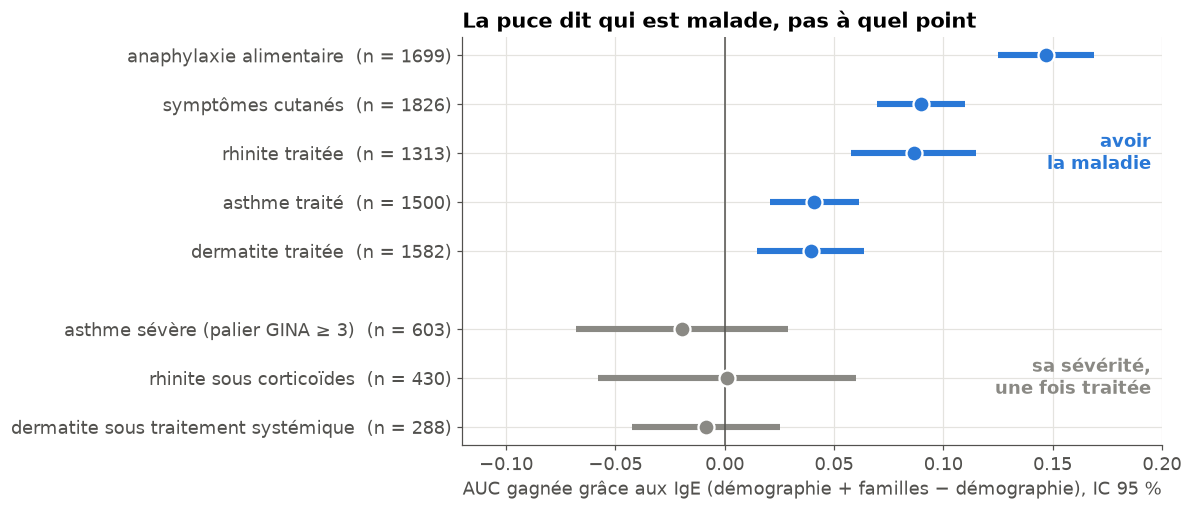

('anaphylaxie alimentaire', np.float64(0.14715371577045352), np.float64(0.12522843454523447), np.float64(0.16907899699567258), False, 1699)
('symptômes cutanés', np.float64(0.08985663502696113), np.float64(0.06957893345077243), np.float64(0.11013433660314983), False, 1826)
('rhinite traitée', np.float64(0.08654328634742901), np.float64(0.0579754376992432), np.float64(0.11511113499561482), False, 1313)
('asthme traité', np.float64(0.0410370942581392), np.float64(0.02073851348680668), np.float64(0.06133567502947172), False, 1500)
('dermatite traitée', np.float64(0.039336054221897995), np.float64(0.014734698942669343), np.float64(0.06393740950112664), False, 1582)
('asthme sévère (palier GINA ≥ 3)', np.float64(-0.019498148148148157), np.float64(-0.06804302252207159), np.float64(0.029046726225775272), True, 603)
('rhinite sous corticoïdes', np.float64(0.0010455799400669917), np.float64(-0.057882128704649295), np.float64(0.059973288584783284), True, 430)
('dermatite sous traitement systémiq

In [6]:
PRES = {"food_anaphylaxis": "anaphylaxie alimentaire", "skin_symptoms": "symptômes cutanés",
        "rhinitis_treatment": "rhinite traitée", "asthma_treatment": "asthme traité", "ad_treatment": "dermatite traitée"}
SEV = {"asthma_step3": "asthme sévère (palier GINA ≥ 3)", "rhinitis_severe": "rhinite sous corticoïdes",
       "ad_systemic": "dermatite sous traitement systémique"}
rows_e = []
for t, lab in {**PRES, **SEV}.items():
    g = v3h[v3h.target == t]
    w = g.pivot_table(index=["repeat", "fold"], columns="features", values="auc")
    m, lo, hi = corrected_ci((w["demo+pfam"] - w["demo"]).to_numpy(), g.n_train.mean(), g.n_test.mean())
    rows_e.append((lab, m, lo, hi, t in SEV, int(g.n_train.mean() + g.n_test.mean())))
fig, ax = plt.subplots(figsize=(11, 4.8))
yy = np.arange(len(rows_e))[::-1].astype(float)
yy[len(PRES):] -= 0.6  # gap between the two groups
for y0, (_lab, m, lo, hi, sev, _n) in zip(yy, rows_e):
    col = GRAY if sev else BLUE
    ax.hlines(y0, lo, hi, color=col, lw=4)
    ax.scatter(m, y0, s=110, color=col, edgecolors="white", linewidths=1.5, zorder=3)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(yy, [f"{r[0]}  (n = {r[5]})" for r in rows_e])
ax.set_xlabel("AUC gagnée grâce aux IgE (démographie + familles − démographie), IC 95 %")
ax.text(0.195, (yy[0] + yy[len(PRES) - 1]) / 2, "avoir\nla maladie", color=BLUE, fontsize=12, va="center",
        ha="right", fontweight="bold")
ax.text(0.195, (yy[len(PRES)] + yy[-1]) / 2, "sa sévérité,\nune fois traitée", color=GRAY, fontsize=12,
        va="center", ha="right", fontweight="bold")
ax.set_xlim(-0.12, 0.2)
ax.set_title("La puce dit qui est malade, pas à quel point", loc="left")
fig.tight_layout()
fig.savefig(FIG / "06_presence_vs_severity.png", dpi=200, bbox_inches="tight")
plt.show()
for r in rows_e:
    print(r)

## F. Ce qu'on voit sans étiquette

La carte t-SNE du notebook 03 (ISAC v1, patients sensibilisés, distance cosinus, perplexité 30, graine 0), recolorée en quatre groupes et étiquetée îlot par îlot pour une slide.

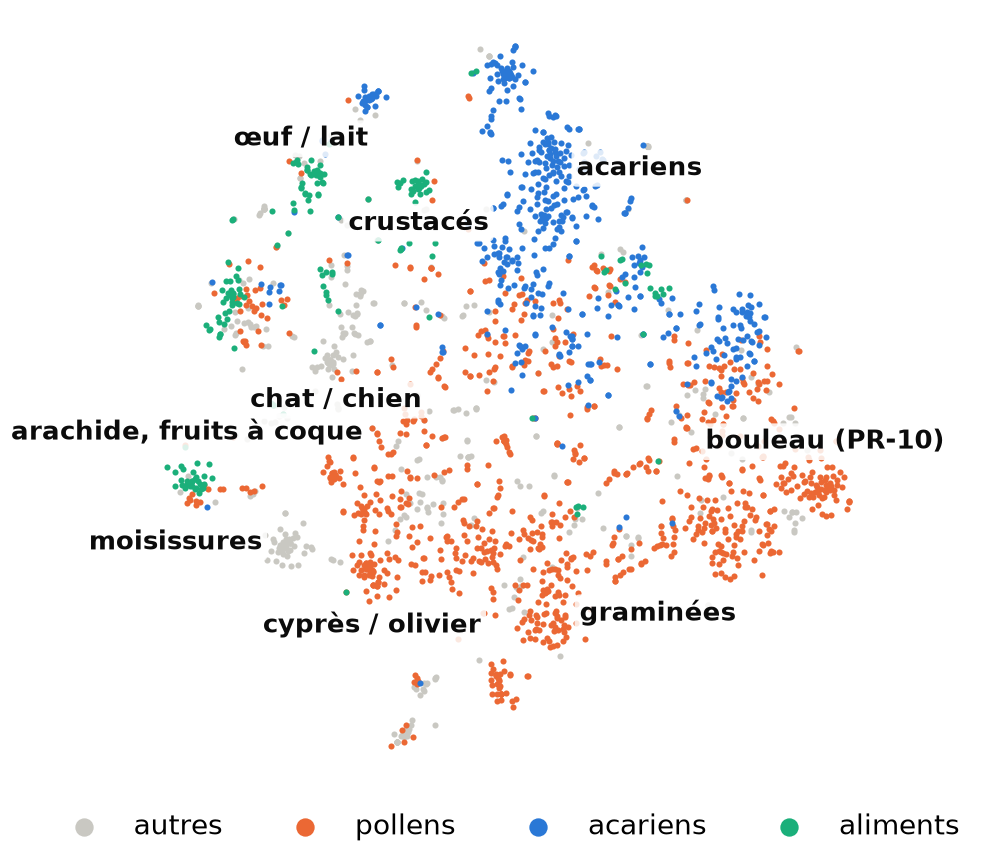

pollens     978
acariens    494
autres      394
aliments    188
Name: count, dtype: int64


In [7]:
import numpy as np
import pandas as pd
from sklearn.manifold import TSNE

# same map as notebook 03 (ISAC v1, sensitized patients, cosine distance, perplexity 30, PCA init,
# seed 0), recoloured with four groups for a slide
THRESHOLD = 0.3
chip_df = df[df["Chip_Type"] == "ISAC_V1"]
cols = [c for c in chip_df.columns[15:] if chip_df[c].notna().mean() > 0.5]
raw_v1 = chip_df.loc[chip_df[cols].notna().all(axis=1), cols]
MARKERS = {
    "mites": ["Der_p_1", "Der_p_2"], "grass": ["Phl_p_1"], "pr10": ["Bet_v_1", "Mal_d_1", "Ara_h_8"],
    "cypress": ["Cup_a_1", "Ole_e_1"], "weeds": ["Art_v_1", "Amb_a_1"], "pets": ["Fel_d_1", "Can_f_1"],
    "mold": ["Alt_a_1"], "nuts": ["Ara_h_2", "Jug_r_1", "Pru_p_3"], "eggmilk": ["Gal_d_1", "Bos_d_8"],
    "shellfish": ["Pen_m_1"],
}
scores = pd.DataFrame({k: np.log1p(raw_v1[v]).mean(axis=1) for k, v in MARKERS.items()})
any_pos = pd.concat([raw_v1[v] >= THRESHOLD for v in MARKERS.values()], axis=1).any(axis=1)
dominant = scores.idxmax(axis=1).where(any_pos, "none")
x = np.log1p(raw_v1.where(raw_v1 >= THRESHOLD, 0))
x = x[(raw_v1 >= THRESHOLD).any(axis=1)]
emb = TSNE(perplexity=30, metric="cosine", init="pca", random_state=0).fit_transform(x)
dom = dominant.loc[x.index].to_numpy()

GROUPS4 = {"mites": "acariens", "grass": "pollens", "pr10": "pollens", "cypress": "pollens", "weeds": "pollens",
           "nuts": "aliments", "eggmilk": "aliments", "shellfish": "aliments"}
g4 = np.array([GROUPS4.get(d, "autres") for d in dom])
COL4 = {"autres": "#c9c8c2", "pollens": ORANGE, "acariens": BLUE, "aliments": "#1baf7a"}
fig, ax = plt.subplots(figsize=(9, 8))
for name in ["autres", "pollens", "acariens", "aliments"]:
    m = g4 == name
    ax.scatter(emb[m, 0], emb[m, 1], s=16, color=COL4[name], linewidths=0, label=name)
# direct labels at the centre of each marker island
ISLANDS = {"mites": "acariens", "grass": "graminées", "pr10": "bouleau (PR-10)", "cypress": "cyprès / olivier",
           "pets": "chat / chien", "mold": "moisissures", "nuts": "arachide, fruits à coque",
           "eggmilk": "œuf / lait", "shellfish": "crustacés"}
span = emb.max(axis=0) - emb.min(axis=0)
radius = 0.04 * span.max()
# label beside the densest point of each group; offsets (fraction of the map) chosen so labels don't collide
OFFSET = {"mites": (0.045, 0, "left", "center"), "eggmilk": (0, 0.05, "center", "bottom"),
          "shellfish": (0, -0.04, "center", "top"), "pets": (0, -0.05, "center", "top"),
          "nuts": (0, 0.05, "center", "bottom"), "mold": (-0.035, 0, "right", "center"),
          "cypress": (0, -0.06, "center", "top"), "grass": (0.05, 0, "left", "center"),
          "pr10": (0, 0.05, "center", "bottom")}
for key, lab in ISLANDS.items():
    pts = emb[dom == key]
    if len(pts) < 15:
        continue
    d = np.linalg.norm(pts[:, None, :] - pts[None, :, :], axis=2)
    cx, cy = pts[(d < radius).sum(axis=1).argmax()]
    dx, dy, ha, va = OFFSET[key]
    ax.text(cx + dx * span[0], cy + dy * span[1], lab, fontsize=17, fontweight="bold", color=INK, ha=ha,
            va=va, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=4, markerscale=3, fontsize=18)
fig.tight_layout()
fig.savefig(FIG / "06_tsne_islands.png", dpi=200, bbox_inches="tight")
plt.show()
print(pd.Series(g4).value_counts())

## G. Le score, version slide

La courbe de risque du notebook 05 (`runs/score/risk_table.csv`), redessinée avec des polices lisibles en projection.

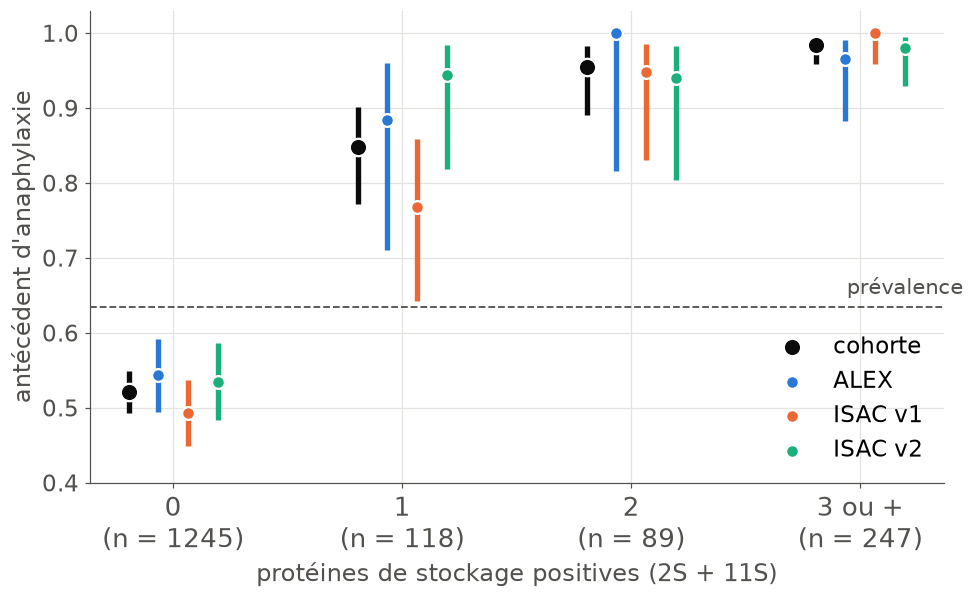

In [8]:
from acc.score import wilson as _wilson  # noqa: F401

risk = pd.read_csv(RUNS / "score" / "risk_table.csv")
CHIP_COL = {"all": INK, "ALEX": BLUE, "ISAC_V1": ORANGE, "ISAC_V2": "#1baf7a"}
CHIP_LAB = {"all": "cohorte", "ALEX": "ALEX", "ISAC_V1": "ISAC v1", "ISAC_V2": "ISAC v2"}
fig, ax = plt.subplots(figsize=(9, 5.6))
for j, g in enumerate(["all", "ALEX", "ISAC_V1", "ISAC_V2"]):
    r = risk[risk.chip == g]
    x = r.level + (j - 1.5) * 0.13
    ax.vlines(x, r.lo, r.hi, color=CHIP_COL[g], lw=3.5)
    ax.scatter(x, r.risk, s=(130 if g == "all" else 70), color=CHIP_COL[g], edgecolors="white", linewidths=1.5,
               zorder=3, label=CHIP_LAB[g])
ax.axhline(0.634, color=MUTED, lw=1.2, ls="--")
ax.text(3.45, 0.645, "prévalence", color=MUTED, fontsize=14, ha="right", va="bottom")
ns = risk[risk.chip == "all"].set_index("level")["n"]
ax.set_xticks(range(4), [f"{k}\n(n = {ns[i]})" for i, k in enumerate(["0", "1", "2", "3 ou +"])], fontsize=17)
ax.tick_params(axis="y", labelsize=15)
ax.set_xlabel("protéines de stockage positives (2S + 11S)", fontsize=16)
ax.set_ylabel("antécédent d'anaphylaxie", fontsize=16)
ax.set_ylim(0.4, 1.03)
ax.legend(frameon=False, fontsize=15, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "06_score_risk.png", dpi=200, bbox_inches="tight")
plt.show()

## H. La carte des familles, version slide

Les 8 familles qui ont au moins une case significative (plus les légumines 11S), en grand. Les 6 autres n'ont aucun effet significatif ; la carte complète est en C.

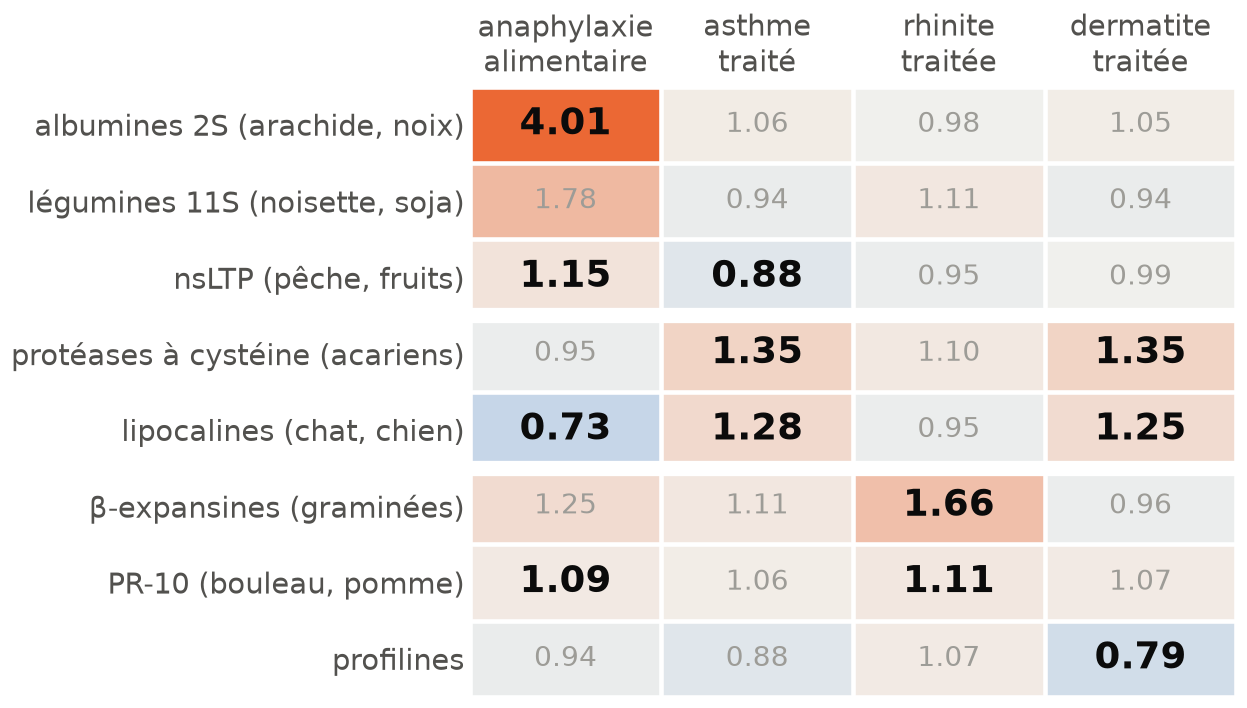

In [9]:
# slide version of map C: only the families with at least one significant cell (+ 11S legumins), bigger type
SLIDE_GROUPS = [
    ["pfam_2S albumin", "pfam_11S legumin", "pfam_nsLTP"],
    ["pfam_Cysteine protease", "pfam_Lipocalin"],
    ["pfam_Beta-expansin", "pfam_PR-10", "pfam_Profilin"],
]
SLIDE_LABELS = {
    "pfam_2S albumin": "albumines 2S (arachide, noix)", "pfam_11S legumin": "légumines 11S (noisette, soja)",
    "pfam_nsLTP": "nsLTP (pêche, fruits)", "pfam_Cysteine protease": "protéases à cystéine (acariens)",
    "pfam_Lipocalin": "lipocalines (chat, chien)", "pfam_Beta-expansin": "β-expansines (graminées)",
    "pfam_PR-10": "PR-10 (bouleau, pomme)", "pfam_Profilin": "profilines",
}
srows = [r for g in SLIDE_GROUPS for r in g]
Ls, Qs = lor.loc[srows], q.loc[srows]
fig, ax = plt.subplots(figsize=(11.5, 6.6))
ax.imshow(Ls.to_numpy(), cmap=cmap, norm=TwoSlopeNorm(0, -lim, lim), aspect="auto")
for i in range(Ls.shape[0]):
    for j in range(Ls.shape[1]):
        sig = Qs.iat[i, j] < 0.05
        ax.text(j, i, f"{np.exp(Ls.iat[i, j]):.2f}", ha="center", va="center", fontsize=24 if sig else 18,
                fontweight="bold" if sig else "normal", color=INK if sig else "#9d9c97")
ax.set_xticks(range(Ls.shape[1]), list(MAP_TARGETS.values()), fontsize=19)
ax.set_yticks(range(Ls.shape[0]), [SLIDE_LABELS[r] for r in srows], fontsize=19)
ax.xaxis.tick_top()
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xticks(np.arange(-0.5, Ls.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, Ls.shape[0]), minor=True)
ax.grid(which="minor", color="white", lw=3)
ax.tick_params(which="both", length=0)
edge = -0.5
for g in SLIDE_GROUPS[:-1]:
    edge += len(g)
    ax.axhline(edge, color="white", lw=10)
fig.tight_layout()
fig.savefig(FIG / "06_family_map_slide.png", dpi=200, bbox_inches="tight")
plt.show()